# REFIT Washing-Machine Disaggregation — Walkthrough

This notebook runs the three analysis stages end-to-end and displays the resulting figures/tables inline. The heavy lifting lives in `../src/*.py` (reusable, testable scripts); this notebook is a thin, narrated wrapper around them. See `../DATA.md`, `../RESULTS.md`, `../Recommendation.md` for the full write-up.

**Before running**: follow the "Getting the data" section in `../README.md` to download and extract the REFIT raw/clean CSVs, and `pip install -r ../requirements.txt`.

In [1]:
import os, sys, json
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = os.path.abspath('..')
SRC = os.path.join(ROOT, 'src')
FIG = os.path.join(ROOT, 'figures')
PROC = os.path.join(ROOT, 'data', 'processed')
sys.path.insert(0, SRC)

pd.set_option('display.width', 140)

## Part 1 — Raw data inspection and cleaning (House 1)

Runs `inspect_house1.py` (prints the raw findings grounding the cleaning thresholds) then `clean_house1.py` (the actual sort/dedupe/null-impossible-values/resample/gap-fill pipeline), and displays the before/after plots. Full narrative and numbers: `../DATA.md`.

In [2]:
import inspect_house1
inspect_house1.main()

rows: 4140886
time range: 2014-06-27 21:57:50 to 2015-07-10 11:56:32
already time-sorted: True
rows where time goes backwards vs previous row: 0


duplicate timestamp rows: 0 = 0.0 %
unique duplicated timestamps: 0

interval stats (seconds):
count    4.140885e+06
mean     7.878297e+00
std      5.826959e+02
min      1.000000e+00
25%      7.000000e+00
50%      7.000000e+00
75%      7.000000e+00
max      7.472520e+05
Name: Time, dtype: float64
median interval: 7.0
% of intervals == 6,7,8s (nominal): 97.85509619320507
count of gaps > 60s: 3603
count of gaps > 600s (10min): 59
count of gaps > 3600s (1hr): 19
largest 10 gaps (s):


3598314    747252.0
3853977    649243.0
639044     390740.0
3167070    376523.0
3070834    198423.0
3659903    179988.0
1252859    135709.0
3154793    129823.0
2998341    108860.0
1894337     86935.0
Name: Time, dtype: float64

NaN counts per column:
Time                0
Unix                0
Aggregate      188973
Appliance1     437890
Appliance2     459468
Appliance3     311961
Appliance4     510963
Appliance5     497223
Appliance6     342337
Appliance7     232752
Appliance8     390705
Appliance9    1911811
dtype: int64

Aggregate stats:
count    3.951913e+06
mean     4.464609e+02
std      8.139717e+02
min      1.500000e+01
25%      1.850000e+02
50%      2.340000e+02
75%      3.630000e+02
max      2.915900e+04
Name: Aggregate, dtype: float64
Aggregate negative count: 0
Aggregate > 20000W count: 74
Aggregate > 15000W count: 104
Aggregate > 10000W count: 10941


Aggregate top 10 values: [29159.0, 28950.0, 28855.0, 24732.0, 24000.0, 24000.0, 24000.0, 24000.0, 24000.0, 24000.0]
Appliance1: max=76677.0, negative=0, >4000W=184
Appliance2: max=66685.0, negative=0, >4000W=22
Appliance3: max=73725.0, negative=0, >4000W=80
Appliance4: max=98301.0, negative=0, >4000W=71
Appliance5: max=73725.0, negative=0, >4000W=65
Appliance6: max=37610.0, negative=0, >4000W=12
Appliance7: max=73725.0, negative=0, >4000W=371
Appliance8: max=98301.0, negative=0, >4000W=91
Appliance9: max=32737.0, negative=0, >4000W=15



rows where sum(appliances) > aggregate (+50W tolerance): 116045 = 2.802419578805116 %


In [3]:
import clean_house1
clean_house1.main()

{
  "raw_rows": 4140886,
  "raw_time_range": [
    "2014-06-27 21:57:50",
    "2015-07-10 11:56:32"
  ],
  "duplicate_timestamp_rows_removed": 0,
  "aggregate_impossible_values_nulled": 74,
  "appliance_impossible_values_nulled": {
    "Appliance1": 184,
    "Appliance2": 22,
    "Appliance3": 80,
    "Appliance4": 71,
    "Appliance5": 65,
    "Appliance6": 12,
    "Appliance7": 371,
    "Appliance8": 91,
    "Appliance9": 15
  },
  "rows_sum_appliances_gt_aggregate": 115217,
  "rows_sum_appliances_gt_aggregate_pct": 2.782,
  "resampled_1min_bins_total": 543720,
  "resampled_1min_bins_fully_missing_before_fill": 53769,
  "remaining_outage_count": 3437,
  "remaining_outage_total_minutes": 770272,
  "largest_outages_minutes": [
    14528,
    12641,
    12450,
    12450,
    12450,
    12450,
    12450,
    12450,
    12450,
    12450
  ],
  "remaining_outage_minutes_by_column": {
    "Aggregate": 53075,
    "Appliance1": 54910,
    "Appliance2": 54944,
    "Appliance3": 54446,
    "App

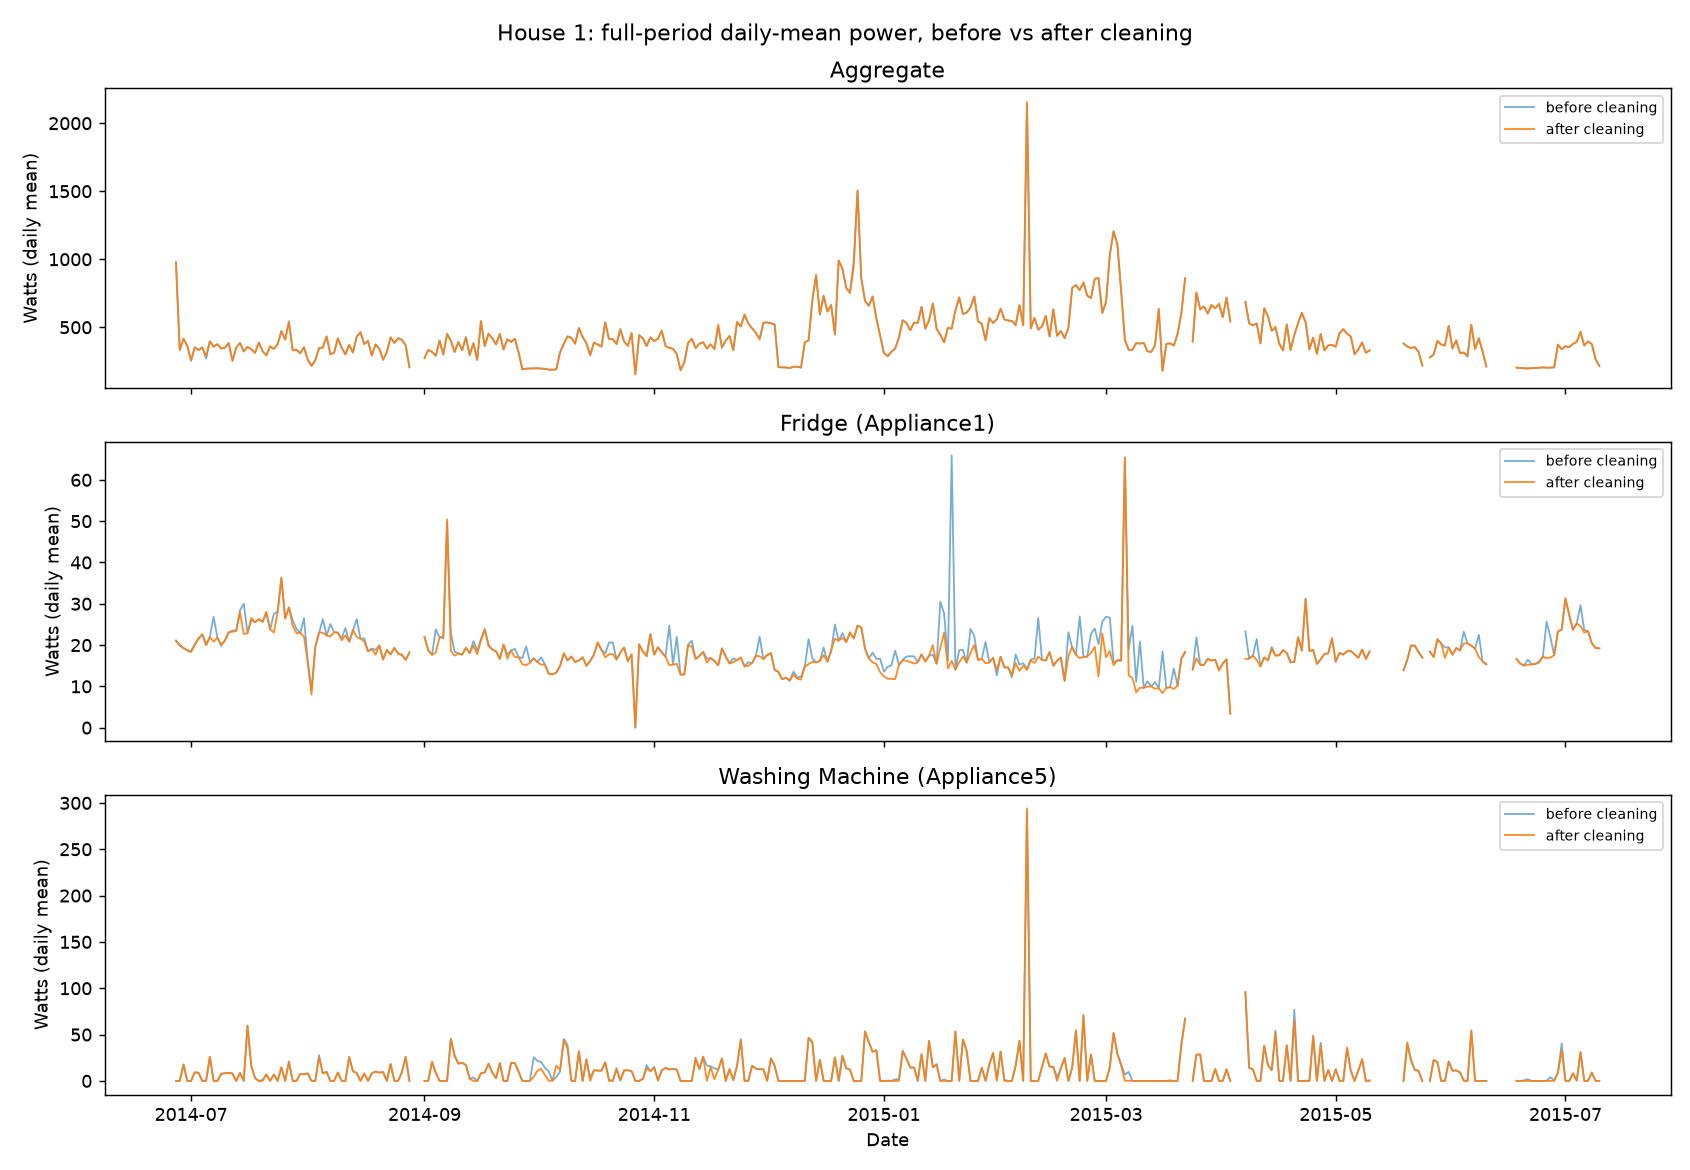

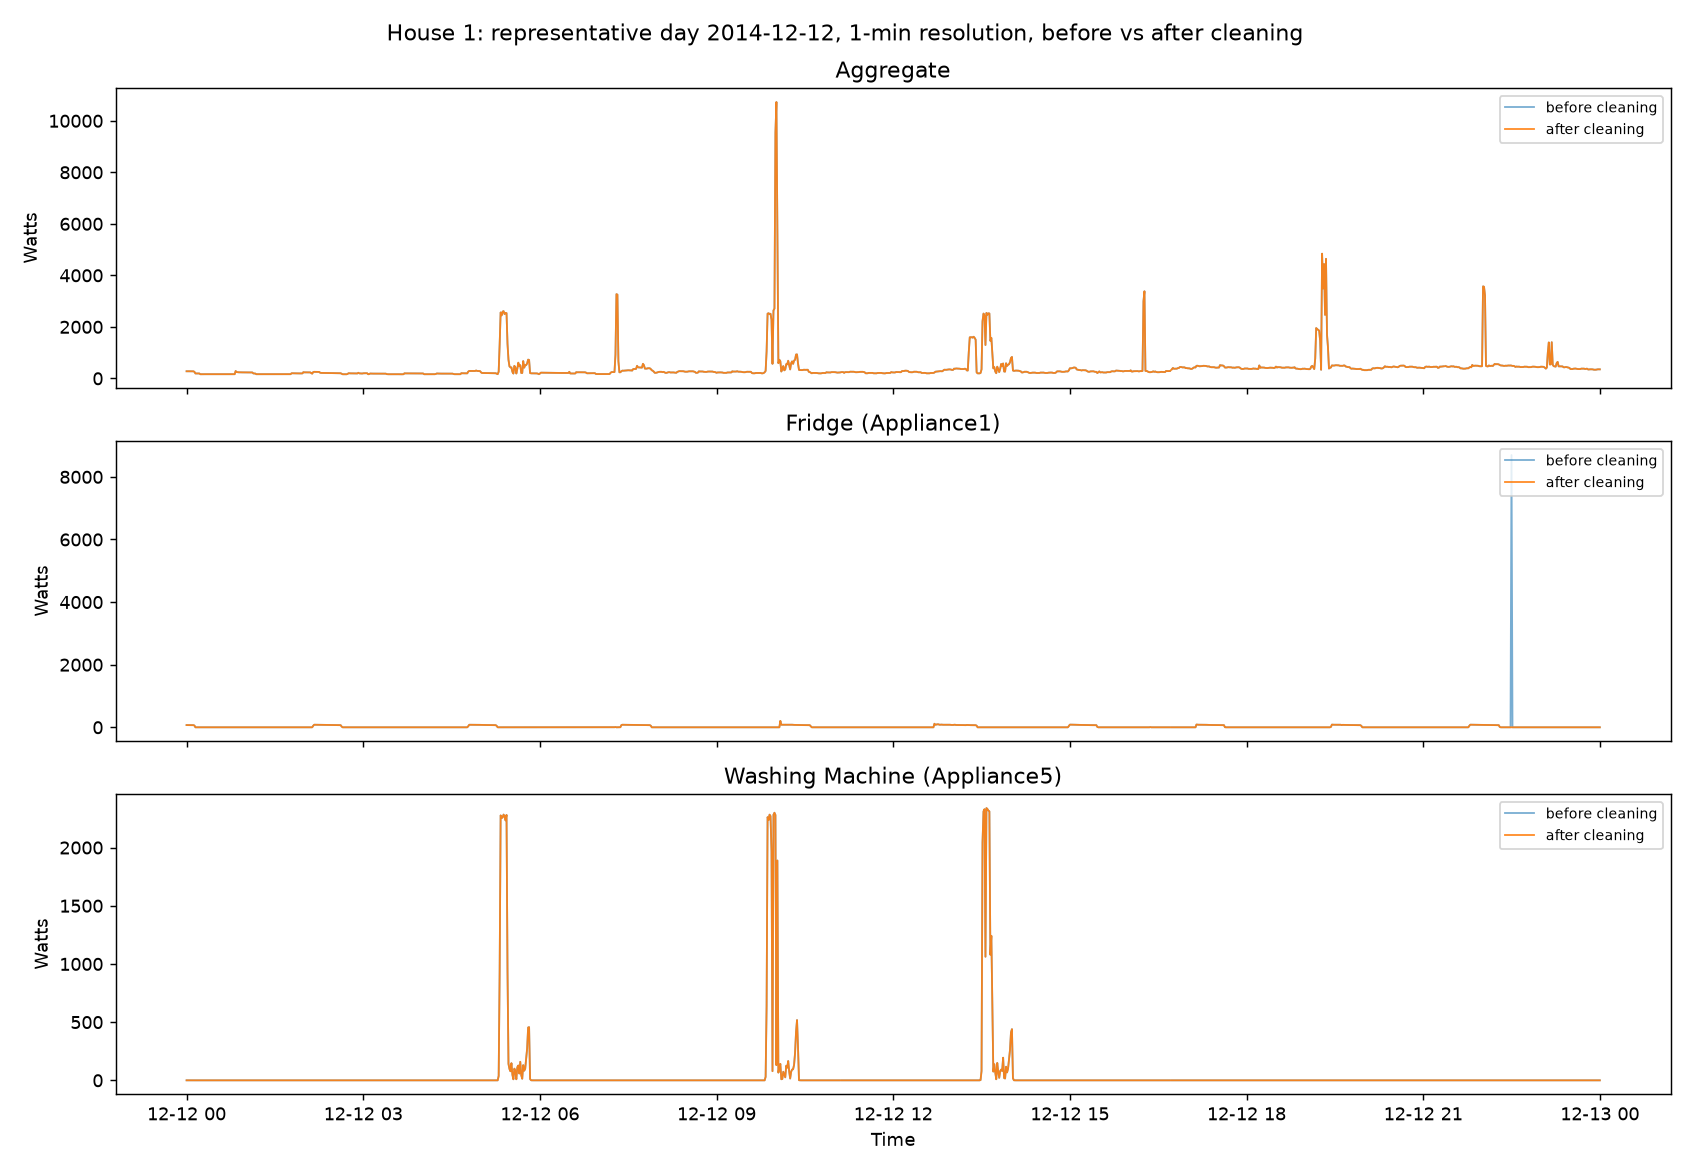

In [4]:
display(Image(filename=f'{FIG}/house1_overview_before_after.png'))
display(Image(filename=f'{FIG}/house1_day_before_after.png'))

## Part 2 — Washing-machine EDA across 8 households (official cleaned data)

Cycle-detection rule, availability table, and plot interpretations: `../RESULTS.md`.

In [5]:
import washing_machine_eda
washing_machine_eda.main()

house 1: 411 cycles, 920091 bins, missing 12.68%


house 2: 339 cycles, 889078 bins, missing 24.47%


house 5: 949 cycles, 933593 bins, missing 11.71%


house 6: 139 cycles, 831480 bins, missing 14.97%


house 7: 859 cycles, 882970 bins, missing 12.71%


house 10: 678 cycles, 845257 bins, missing 10.65%


house 19: 270 cycles, 677470 bins, missing 6.39%


house 20: 198 cycles, 662864 bins, missing 5.97%



=== Availability ===
 house  wm_channel               start                 end  total_days  total_1min_bins  missing_pct  off_pct  n_cycles_detected  available_days  cycles_per_week
     1           5 2013-10-09 13:06:00 2015-07-10 11:56:00       639.0           920091        12.68    98.29                411           557.9             5.16
     2           2 2013-09-17 22:08:00 2015-05-28 08:05:00       617.4           889078        24.47    96.24                339           466.3             5.09
     5           3 2013-09-26 09:56:00 2015-07-06 17:48:00       648.3           933593        11.71    93.36                949           572.4            11.61
     6           2 2013-11-28 12:15:00 2015-06-28 22:14:00       577.4           831480        14.97    98.40                139           491.0             1.98
     7           5 2013-11-01 22:01:00 2015-07-08 02:10:00       613.2           882970        12.71    92.70                859           535.2            11.23
    10


Saved availability/cycles tables and 4 figures to figures/.


,house,wm_channel,start,end,total_days,total_1min_bins,missing_pct,off_pct,n_cycles_detected,available_days,cycles_per_week
0,1,5,2013-10-09 13:06:00,2015-07-10 11:56:00,639.0,920091,12.68,98.29,411,557.9,5.16
1,2,2,2013-09-17 22:08:00,2015-05-28 08:05:00,617.4,889078,24.47,96.24,339,466.3,5.09
2,5,3,2013-09-26 09:56:00,2015-07-06 17:48:00,648.3,933593,11.71,93.36,949,572.4,11.61
3,6,2,2013-11-28 12:15:00,2015-06-28 22:14:00,577.4,831480,14.97,98.40,139,491.0,1.98
4,7,5,2013-11-01 22:01:00,2015-07-08 02:10:00,613.2,882970,12.71,92.70,859,535.2,11.23
5,10,5,2013-11-20 11:31:00,2015-06-30 11:07:00,587.0,845257,10.65,92.04,678,524.5,9.05
6,19,2,2014-03-06 16:23:00,2015-06-20 03:32:00,470.5,677470,6.39,96.36,270,440.4,4.29
7,20,4,2014-03-20 12:01:00,2015-06-23 19:44:00,460.3,662864,5.97,97.62,198,432.8,3.20


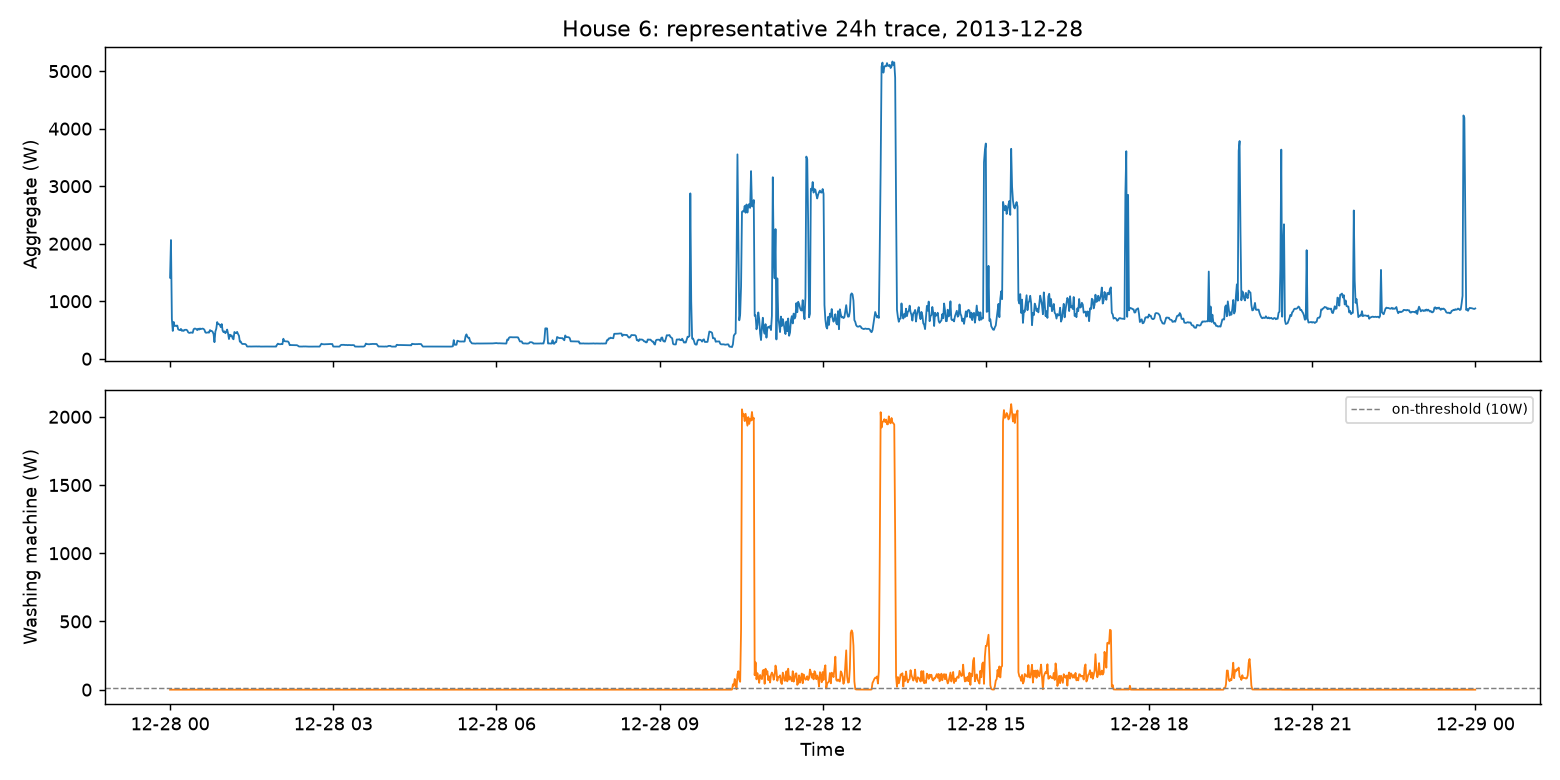

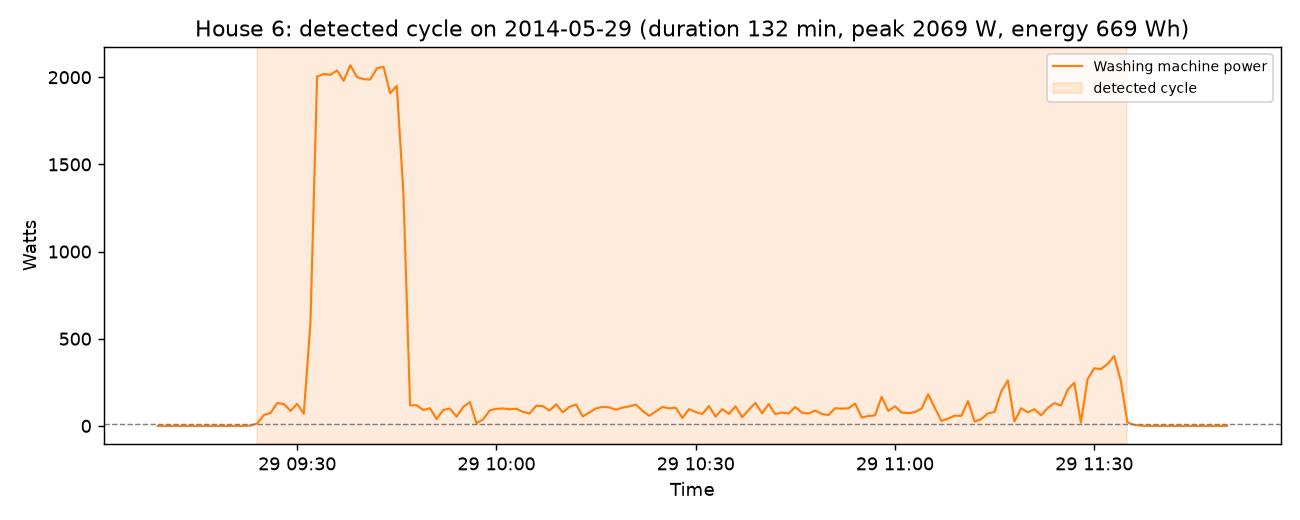

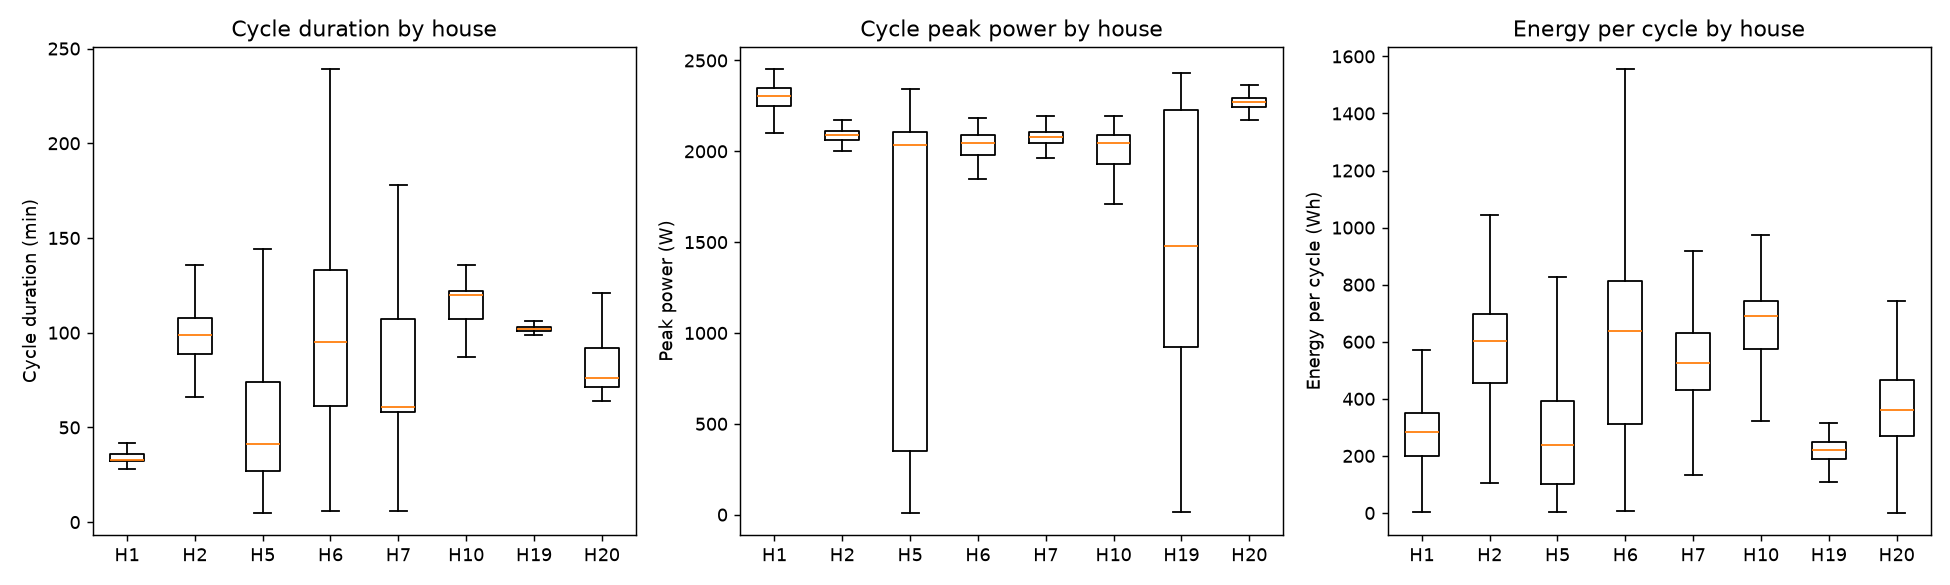

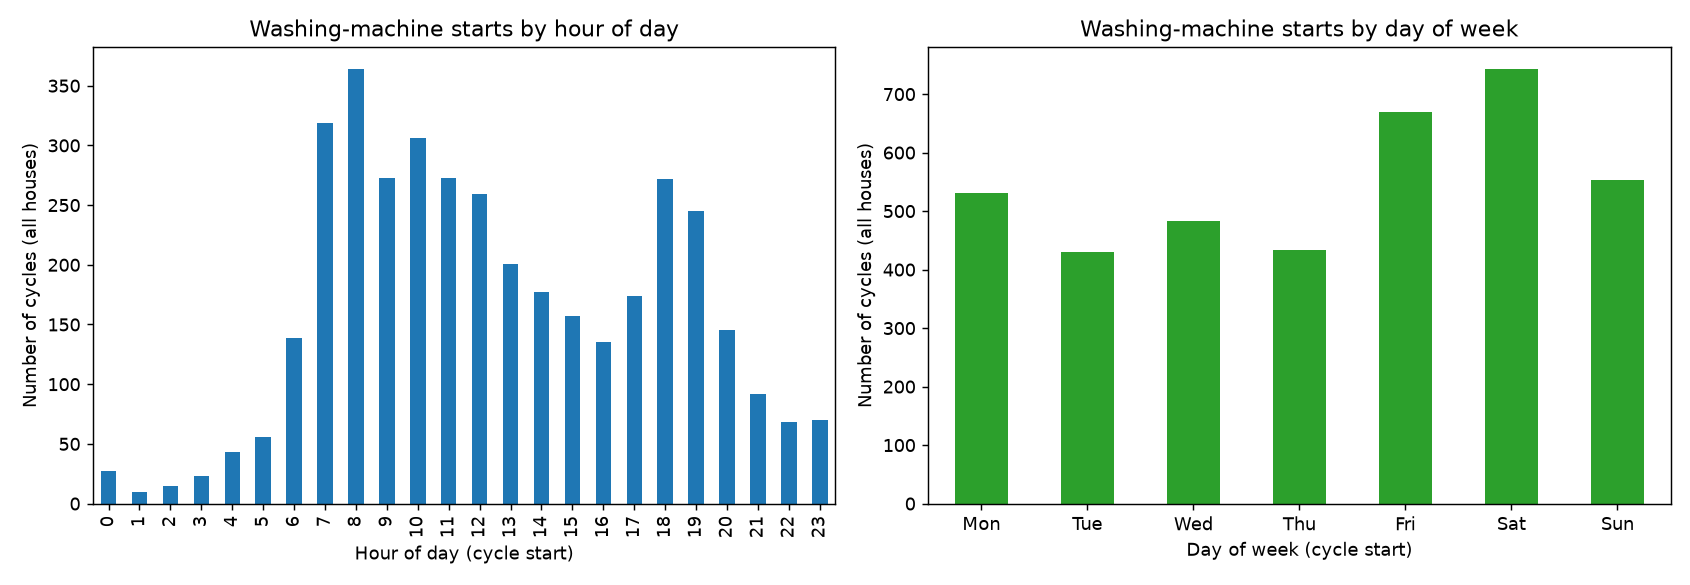

In [6]:
display(pd.read_csv(f'{PROC}/wm_availability.csv'))
for f in ['wm_24h_trace_house6.png', 'wm_detected_cycle_house6.png', 'wm_cross_house_comparison.png', 'wm_usage_patterns.png']:
    display(Image(filename=f'{FIG}/{f}'))

## Part 3 — Disaggregation model: baselines, LightGBM, household-split vs time-split, and a per-household-normalized-feature iteration

Full discussion, metrics interpretation and failure analysis: `../RESULTS.md`. This cell takes ~30s (trains 3 LightGBM models on ~2-4M rows each).

In [7]:
import disaggregation_model
disaggregation_model.main()

Loading + building features for train/val/test houses...


train rows=3006175, val rows=770726, test rows=2012705
n features=29


                     label  MAE_W  RMSE_W    SAE  on_off_F1  on_off_precision  on_off_recall  n_rows
       baseline_always_off  16.14  148.60 1.0000     0.0000            0.0000         0.0000 2012705
   baseline_hourly_profile  28.92  147.68 0.0936     0.1192            0.0655         0.6625 2012705
            lightgbm_model  16.15  148.59 0.9991     0.0000            0.0000         0.0000 2012705
lightgbm_model_active_only 300.96  642.20 0.9997     0.0000            0.0000         0.0000  107752
          lightgbm_house10  31.93  214.13 0.9992     0.0000            0.0000         0.0000  755223
          lightgbm_house19   5.66   57.74 0.9995     0.0000            0.0000         0.0000  634189
          lightgbm_house20   7.70  111.13 0.9980     0.0000            0.0000         0.0000  623293

Top 10 features by gain:
         feature   importance
 agg_roll_min_60 25620.766418
agg_roll_mean_60 12833.735016
        hour_cos  7079.135925
         dow_sin  6747.050873
 agg_roll_std_60

train rows=4052721, val rows=868441, test rows=868444


[50]	valid_0's l1: 21.0844


...

[150]	valid_0's l1: 20.9866


[200]	valid_0's l1: 20.9558


                            label  MAE_W  RMSE_W    SAE  on_off_F1  on_off_precision  on_off_recall  n_rows
    timesplit_baseline_always_off  20.13  170.82 1.0000     0.0000            0.0000         0.0000  868444
timesplit_baseline_hourly_profile  34.48  169.24 0.1589     0.1324            0.0723         0.7893  868444
         timesplit_lightgbm_model  19.57  164.06 0.9075     0.4471            0.6459         0.3419  868444
   timesplit_lightgbm_active_only 330.97  685.68 0.9379     0.5096            1.0000         0.3419   49645
best_iteration=196

=== Experiment A, per-household-normalized features ===


train rows=3006175, val rows=770726, test rows=2012705
n features=29


                          label  MAE_W  RMSE_W    SAE  on_off_F1  on_off_precision  on_off_recall  n_rows
       norm_baseline_always_off  16.14  148.60 1.0000     0.0000            0.0000         0.0000 2012705
   norm_baseline_hourly_profile  28.92  147.68 0.0936     0.1192            0.0655         0.6625 2012705
            norm_lightgbm_model  16.15  148.60 0.9994     0.0000            0.0000         0.0000 2012705
norm_lightgbm_model_active_only 301.00  642.22 0.9999     0.0000            0.0000         0.0000  107752
          norm_lightgbm_house10  31.93  214.13 0.9995     0.0000            0.0000         0.0000  755223
          norm_lightgbm_house19   5.66   57.74 0.9994     0.0000            0.0000         0.0000  634189
          norm_lightgbm_house20   7.70  111.14 0.9993     0.0000            0.0000         0.0000  623293

Top 10 features by gain (normalized):
             feature   importance
agg_roll_max_60_norm 20310.443893
 agg_roll_std_5_norm 18500.599060
           

Experiment A: household split (fully held-out test houses)


,label,MAE_W,RMSE_W,SAE,on_off_F1,on_off_precision,on_off_recall,n_rows
0,baseline_always_off,16.14,148.60,1.0000,0.0000,0.0000,0.0000,2012705
1,baseline_hourly_profile,28.92,147.68,0.0936,0.1192,0.0655,0.6625,2012705
2,lightgbm_model,16.15,148.59,0.9991,0.0000,0.0000,0.0000,2012705
3,lightgbm_model_active_only,300.96,642.20,0.9997,0.0000,0.0000,0.0000,107752
4,lightgbm_house10,31.93,214.13,0.9992,0.0000,0.0000,0.0000,755223
5,lightgbm_house19,5.66,57.74,0.9995,0.0000,0.0000,0.0000,634189
6,lightgbm_house20,7.70,111.13,0.9980,0.0000,0.0000,0.0000,623293


Experiment B: time split (seen households, later time period)


,label,MAE_W,RMSE_W,SAE,on_off_F1,on_off_precision,on_off_recall,n_rows
0,timesplit_baseline_always_off,20.13,170.82,1.0000,0.0000,0.0000,0.0000,868444
1,timesplit_baseline_hourly_profile,34.48,169.24,0.1589,0.1324,0.0723,0.7893,868444
2,timesplit_lightgbm_model,19.57,164.06,0.9075,0.4471,0.6459,0.3419,868444
3,timesplit_lightgbm_active_only,330.97,685.68,0.9379,0.5096,1.0000,0.3419,49645


Experiment A, re-run with per-household-normalized features (see RESULTS.md "Model iteration")


,label,MAE_W,RMSE_W,SAE,on_off_F1,on_off_precision,on_off_recall,n_rows
0,norm_baseline_always_off,16.14,148.60,1.0000,0.0000,0.0000,0.0000,2012705
1,norm_baseline_hourly_profile,28.92,147.68,0.0936,0.1192,0.0655,0.6625,2012705
2,norm_lightgbm_model,16.15,148.60,0.9994,0.0000,0.0000,0.0000,2012705
3,norm_lightgbm_model_active_only,301.00,642.22,0.9999,0.0000,0.0000,0.0000,107752
4,norm_lightgbm_house10,31.93,214.13,0.9995,0.0000,0.0000,0.0000,755223
5,norm_lightgbm_house19,5.66,57.74,0.9994,0.0000,0.0000,0.0000,634189
6,norm_lightgbm_house20,7.70,111.14,0.9993,0.0000,0.0000,0.0000,623293


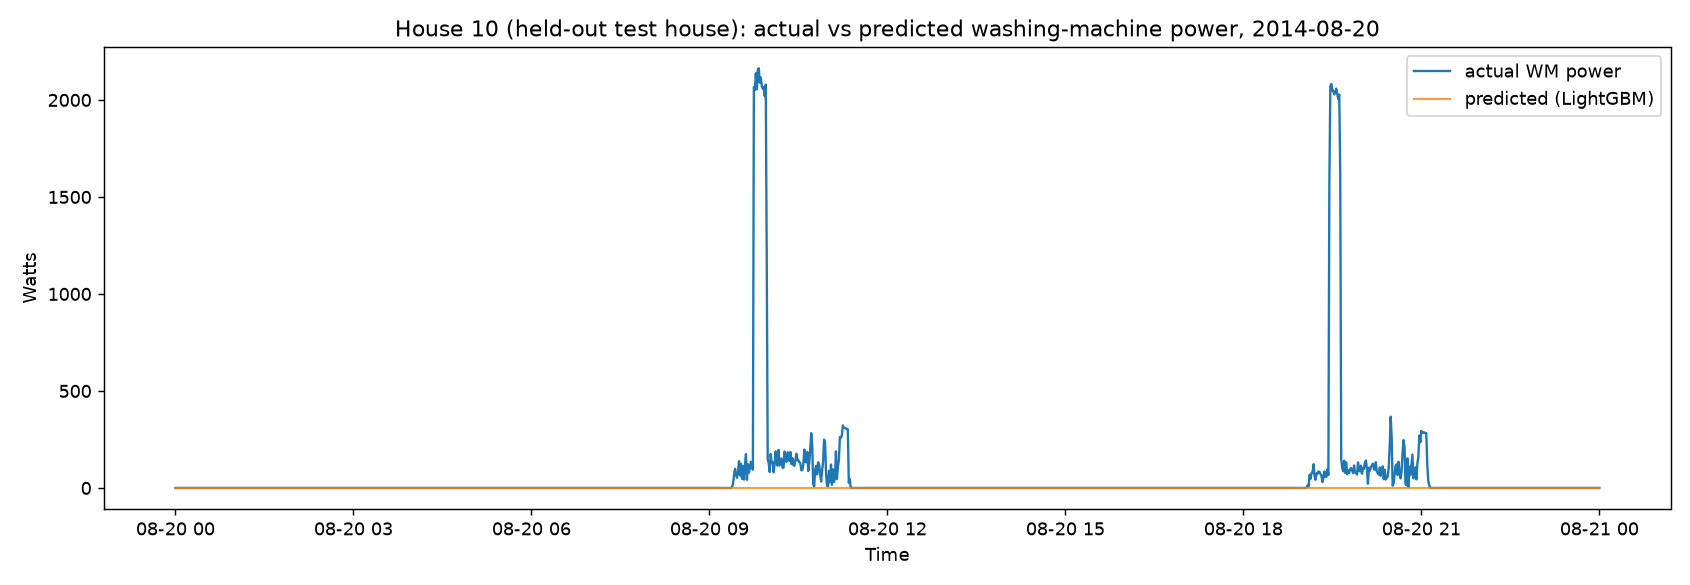

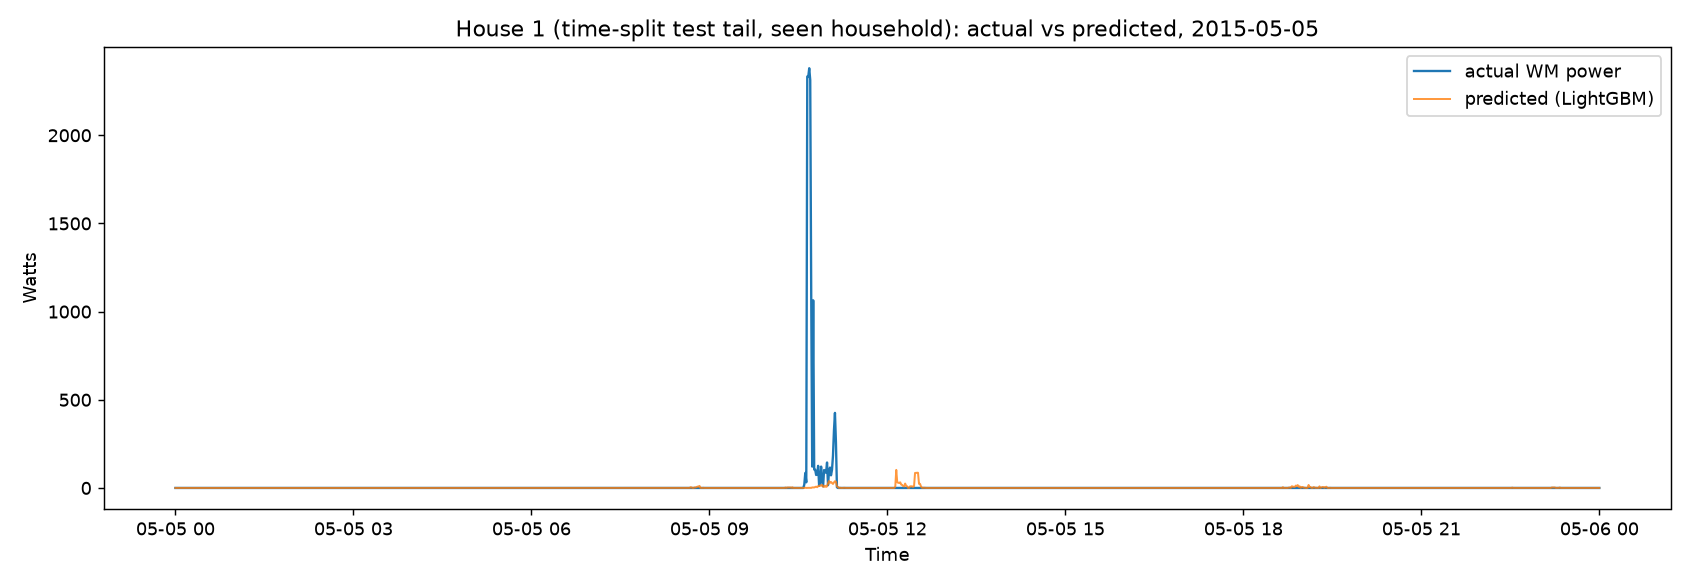

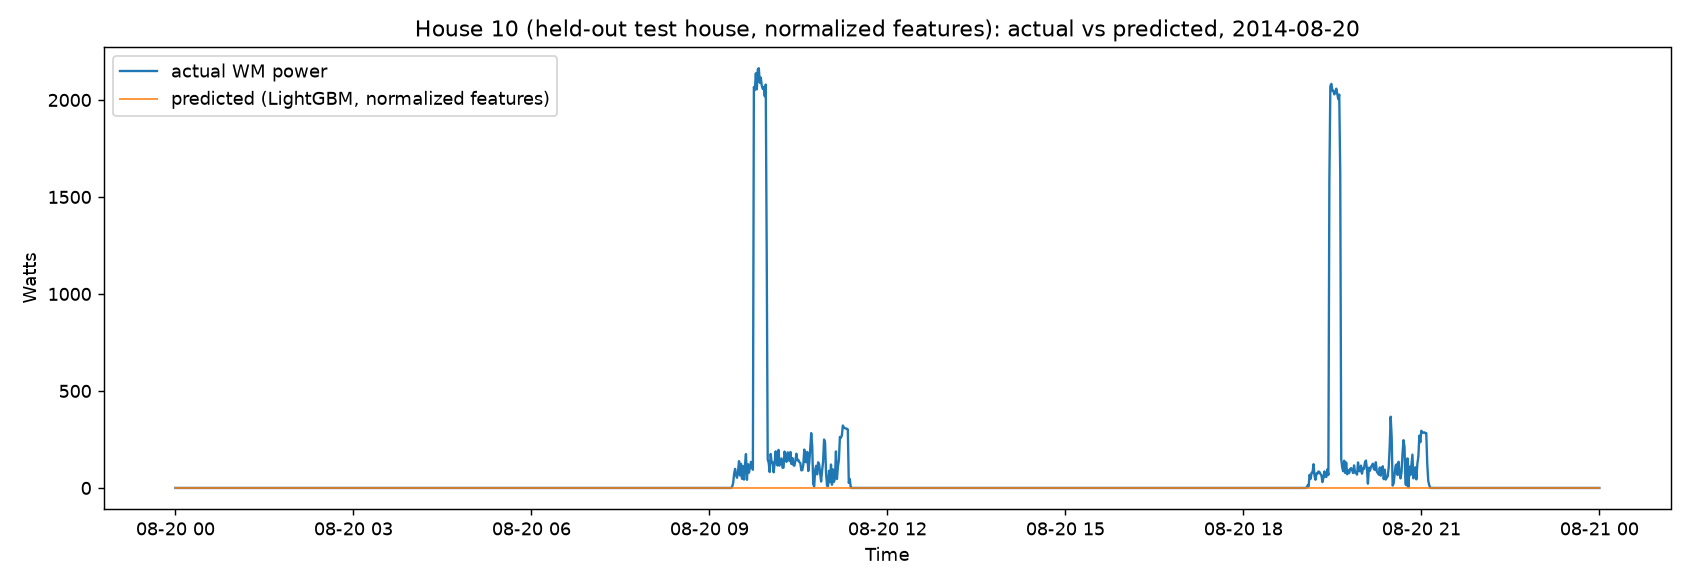

In [8]:
print('Experiment A: household split (fully held-out test houses)')
display(pd.read_csv(f'{PROC}/model_results.csv'))
print('Experiment B: time split (seen households, later time period)')
display(pd.read_csv(f'{PROC}/model_results_timesplit.csv'))
print('Experiment A, re-run with per-household-normalized features (see RESULTS.md "Model iteration")')
display(pd.read_csv(f'{PROC}/model_results_normalized.csv'))
display(Image(filename=f'{FIG}/model_actual_vs_predicted_house10.png'))
display(Image(filename=f'{FIG}/model_actual_vs_predicted_timesplit_house1.png'))
display(Image(filename=f'{FIG}/model_actual_vs_predicted_house10_normalized.png'))